In [27]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colormaps
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import statsmodels.api as sm

import os
os.chdir('/Users/jweiss/Documents/DALLab/')

from utils.my_funcs import *

In [28]:
condition_map = {
    2: '5k macs',
    3: '10k macs',
    4: '1k escs, 9k macs',
    5: '5k escs, 5k macs',
    6: '9k escs, 1k macs',
    7: '10k escs',
    8: '5k escs'
}

color_gradient = colormaps['RdYlBu']

In [29]:
df = pd.read_csv('16/data/luminex_wrangled.csv')
df['analyte'] = df['analyte'].str.split('_').str[0]

# aggregate by condition
df = df.dropna(subset='concentration').groupby(['condition', 'bio_rep', 'analyte', 'saw_il1b'])[['concentration']].mean().reset_index()

# pivot such that each row represents a condition and each column represents an analyte
df = df.pivot_table(index=['condition', 'bio_rep', 'saw_il1b'], columns='analyte', values='concentration').reset_index()

# only IL-1B+
#df = df[df['saw_il1b']]
#df = df.drop('saw_il1b', axis=1)

# drop any columns that contain NaN
df = df.dropna(axis=1)

# drop condition 6 (far too funky)
#df = df[df['condition'] != 6]

analytes = df.columns[3:]
df

analyte,condition,bio_rep,saw_il1b,CCL3,CCL4,CCL5,CXCL10,CXCL13,IL10,IL1ra,IL4,MMP12,SLPI,TNFa,VCAM1
0,2,B,True,196.315587,180.255075,18.683765,0.811973,17.334325,0.878917,516.420478,14.250662,21.326560,135.444983,22.089125,3991.900206
1,2,C,True,328.008249,312.403835,18.750801,0.847524,18.433529,1.465704,1440.765436,14.155242,21.224241,135.444983,46.381542,3926.820733
2,2,D,True,372.433310,346.689129,18.885011,0.859387,18.937332,1.685359,1584.490651,14.345939,21.445930,135.444983,51.205990,3991.900206
3,2,E,False,55.700796,90.715901,18.482931,0.711559,16.370035,0.463410,127.270766,14.345939,21.582350,133.562245,3.389384,3894.196114
4,2,F,False,52.545943,92.515446,18.549830,0.829742,15.837237,0.484438,133.962067,15.009005,21.599402,131.665457,3.368707,3926.820733
5,2,G,False,47.442709,88.555135,18.683765,0.841595,15.685971,0.437230,59.473369,13.772112,21.565298,130.711660,3.039699,3861.513712
6,3,B,True,155.337250,128.967269,18.750801,0.966412,16.689645,0.489707,181.903061,13.963970,21.138974,129.754186,14.945552,3894.196114
7,3,C,True,148.330087,133.498633,18.449499,0.853455,16.805152,0.563920,213.870572,14.630929,21.428877,133.562245,17.530329,3861.513712
8,3,D,True,155.438312,124.792669,18.885011,0.841595,16.895153,0.463410,121.778541,14.345939,21.428877,136.381213,13.144873,3861.513712
9,3,E,False,54.928211,89.275555,18.817883,0.835668,15.685971,0.298176,70.536528,13.675959,21.326560,139.169934,3.826538,3926.820733


### Cluster cytokines

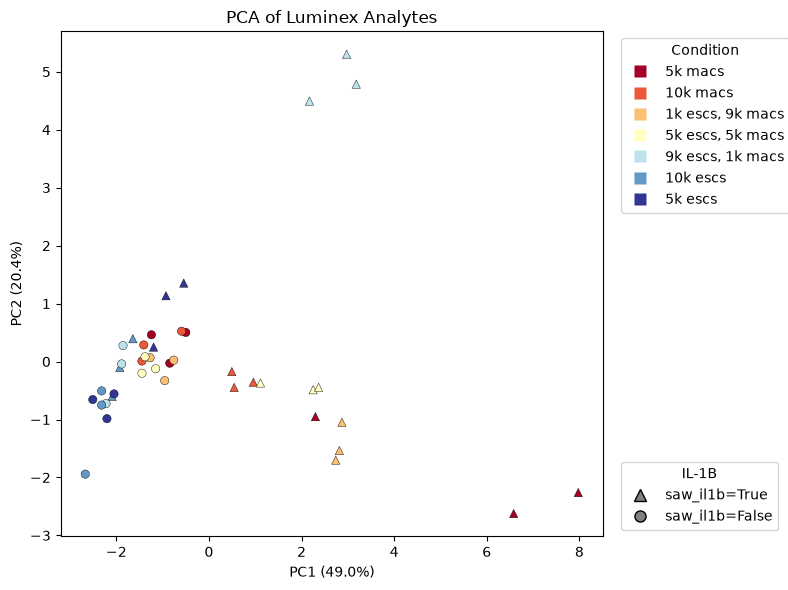

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",4
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [30]:
# including +/- IL1B

pca_analytes(df, analytes)

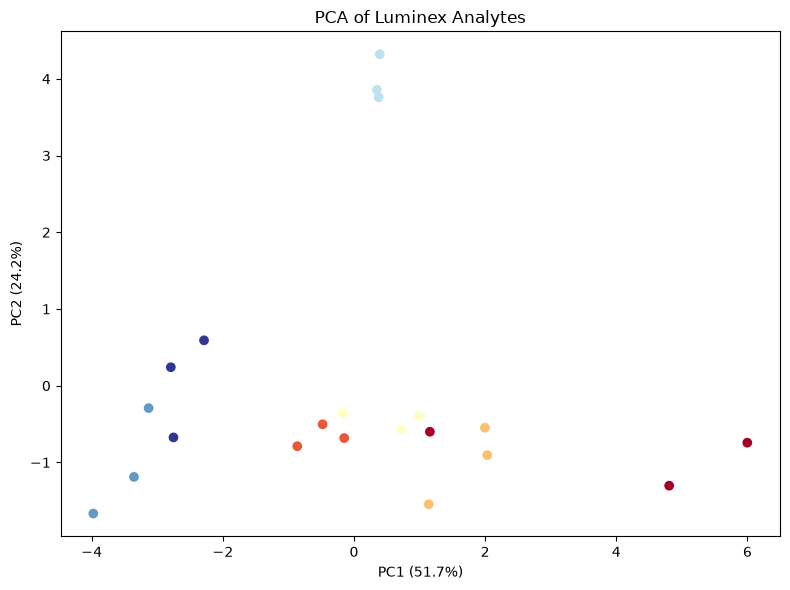

In [31]:
# only IL1B+ condition

pca = pca_analytes(df, analytes, il1b_pos_only=True)

Text(0.5, 1.0, 'PC2 Loadings')

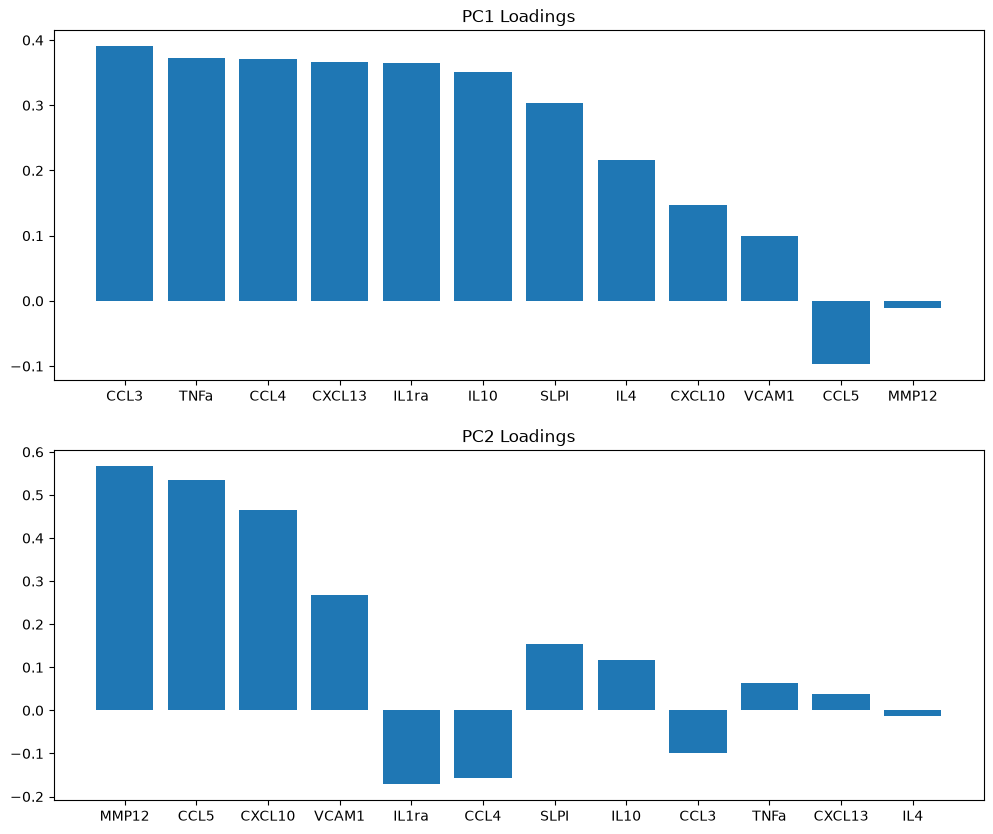

In [32]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=df.drop(columns=['condition', 'bio_rep', 'saw_il1b']).columns,
    columns=['PC1', 'PC2', 'PC3', 'PC4']
)

fig, axs = plt.subplots(2, 1, figsize=(12, 10))

axs[0].bar(loadings['PC1'].sort_values(key=abs, ascending=False).index,
        loadings['PC1'].sort_values(key=abs, ascending=False).values)
axs[0].set_title('PC1 Loadings')

axs[1].bar(loadings['PC2'].sort_values(key=abs, ascending=False).index,
        loadings['PC2'].sort_values(key=abs, ascending=False).values)
axs[1].set_title('PC2 Loadings')

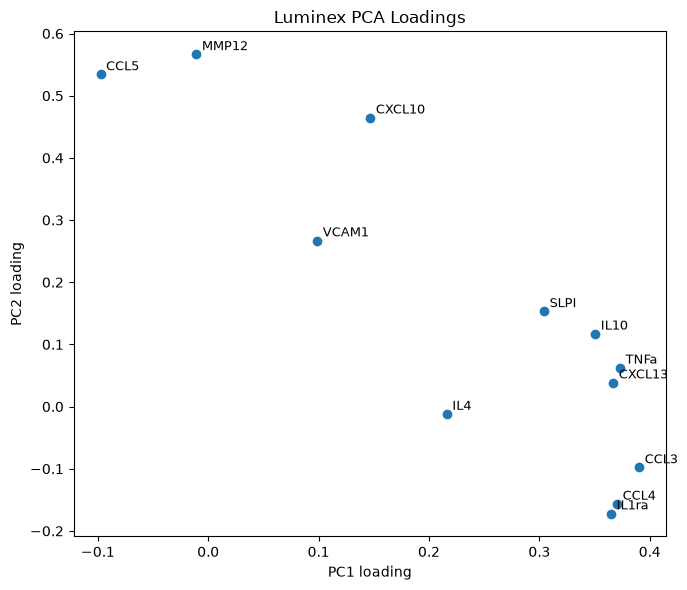

In [33]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(loadings["PC1"], loadings["PC2"])

for analyte, row in loadings.iterrows():
    ax.annotate(
        analyte,
        (row["PC1"], row["PC2"]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("PC1 loading")
ax.set_ylabel("PC2 loading")
ax.set_title("Luminex PCA Loadings")

plt.tight_layout()
plt.show()

In [34]:
import ipywidgets as widgets
from IPython.display import display, clear_output

n_graphs = len(analytes)
current = {'i': 0}

output = widgets.Output()
btn_prev = widgets.Button(description='◀ Previous')
btn_next = widgets.Button(description='Next ▶')
label = widgets.Label()

def render():
    label.value = f"Graph {current['i']+1} / {n_graphs}"
    with output:
        clear_output(wait=True)
        cytokine = analytes[current['i']]

        fig, axes = plt.subplots(1, 2, figsize=(14,6))

        df_pos = df[df['saw_il1b']]
        df_neg = df[~df['saw_il1b']]

        plot_cytokine(df_neg, cytokine, axes[0], title_suffix=' (IL-1B-)')
        plot_cytokine(df_pos, cytokine, axes[1], title_suffix=' (IL-1B+)')

        fig.tight_layout()
        plt.show()

def on_next(b):
    current['i'] = min(current['i'] + 1, n_graphs - 1)
    render()

def on_prev(b):
    current['i'] = max(current['i'] - 1, 0)
    render()

btn_next.on_click(on_next)
btn_prev.on_click(on_prev)

display(widgets.HBox([btn_prev, btn_next]), label, output)
render()

Label(value='')

Output()

In [35]:
df = df.set_index(['condition', 'bio_rep'])
df_z = (df - df.mean()) / df.std()


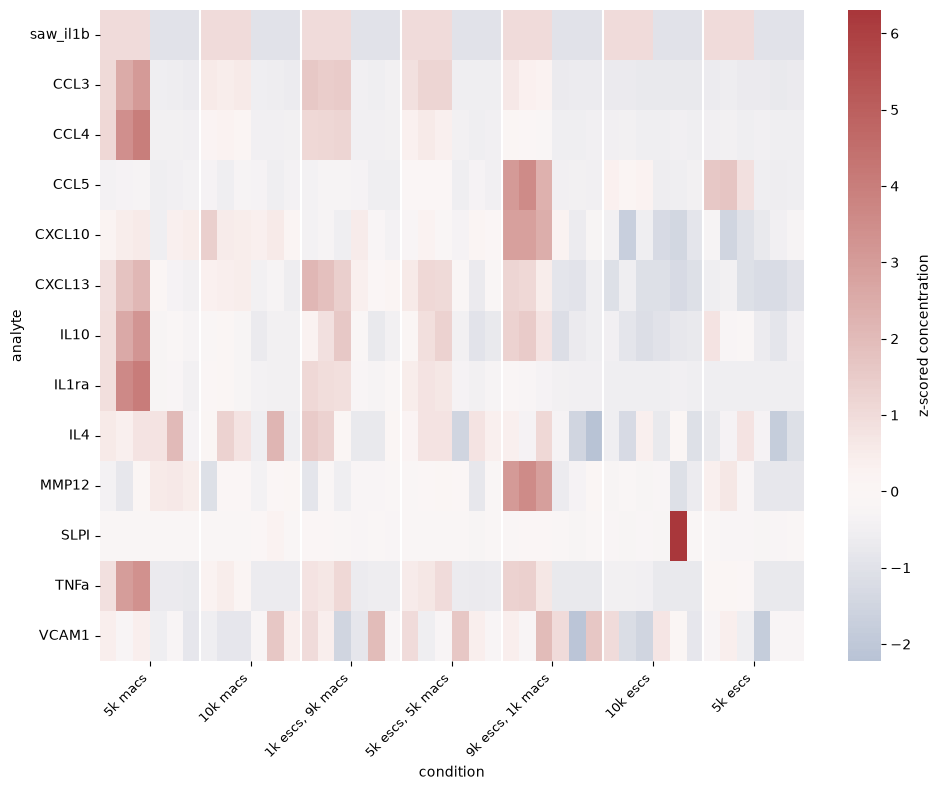

In [36]:
plot_df = df_z.T  # transpose: analytes as rows, samples as columns

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(plot_df, cmap='vlag', center=0, annot=False, cbar_kws={'label': 'z-scored concentration'}, ax=ax)

# pull condition labels directly from the MultiIndex level
conditions = df_z.index.get_level_values('condition')
unique_conditions = conditions.unique()
condition_labels = [condition_map.get(condition) for condition in unique_conditions]

# group sizes may vary — compute boundaries dynamically rather than assuming a fixed size
group_sizes = conditions.value_counts().reindex(unique_conditions)
boundaries = np.concatenate([[0], group_sizes.cumsum().values])
tick_positions = (boundaries[:-1] + boundaries[1:]) / 2

ax.set_xticks([])
ax.set_xticks(tick_positions)
ax.set_xticklabels(condition_labels, rotation=45, ha='right', fontsize=9)

for b in boundaries[1:-1]:
    ax.axvline(b, color='white', linewidth=1.5)

ax.set_xlabel('condition')
ax.set_ylabel('analyte')
plt.tight_layout()
plt.show()

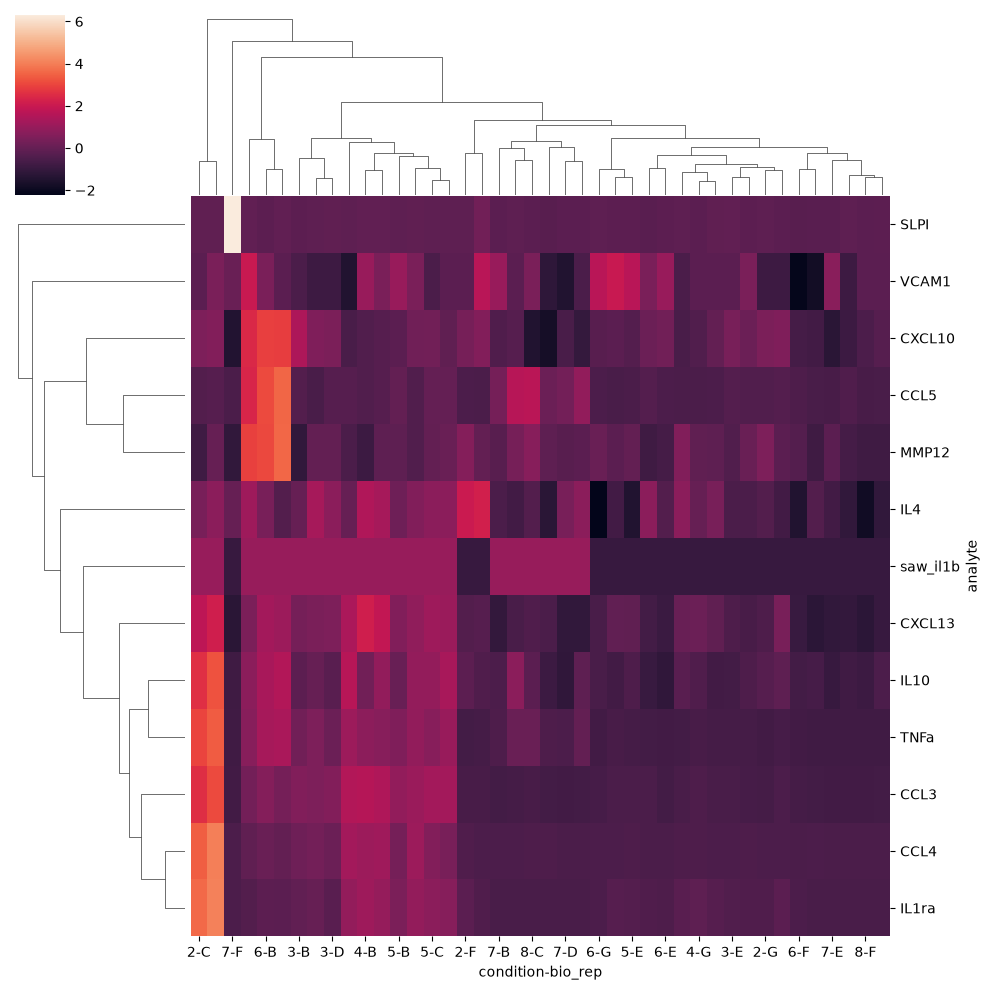

In [37]:
sns.clustermap(df_z.T)

### Adding in accurate cell counts (from DAPI/cell trace imaging)

In [38]:
cell_counts = pd.read_csv('16/data/well_summary.csv', index_col=0)

cell_counts['bio_rep'] = cell_counts['well_id'].str.extract(r'([A-Za-z]+)')
cell_counts['condition'] = cell_counts['well_id'].str.extract(r'(\d+)').astype(int)
cell_counts = cell_counts.drop(['well_id'], axis=1)

cell_counts.head()

,num cells,num ESCs,num macrophages,bio_rep,condition
0,4452,83,4369,B,2
1,1871,232,1639,B,3
2,1935,276,1659,B,4
3,1150,538,612,B,5
4,4958,4594,364,B,6


In [39]:
# MERGE

df = df.reset_index().merge(
    cell_counts,
    on=['condition', 'bio_rep']
)
#df = df.set_index(['condition', 'bio_rep'])
df

,condition,bio_rep,saw_il1b,CCL3,CCL4,CCL5,CXCL10,CXCL13,IL10,IL1ra,IL4,MMP12,SLPI,TNFa,VCAM1,num cells,num ESCs,num macrophages
0,2,B,True,196.315587,180.255075,18.683765,0.811973,17.334325,0.878917,516.420478,14.250662,21.326560,135.444983,22.089125,3991.900206,4452,83,4369
1,2,C,True,328.008249,312.403835,18.750801,0.847524,18.433529,1.465704,1440.765436,14.155242,21.224241,135.444983,46.381542,3926.820733,4356,112,4244
2,2,D,True,372.433310,346.689129,18.885011,0.859387,18.937332,1.685359,1584.490651,14.345939,21.445930,135.444983,51.205990,3991.900206,3766,159,3607
3,2,E,False,55.700796,90.715901,18.482931,0.711559,16.370035,0.463410,127.270766,14.345939,21.582350,133.562245,3.389384,3894.196114,4182,92,4090
4,2,F,False,52.545943,92.515446,18.549830,0.829742,15.837237,0.484438,133.962067,15.009005,21.599402,131.665457,3.368707,3926.820733,3953,238,3715
5,2,G,False,47.442709,88.555135,18.683765,0.841595,15.685971,0.437230,59.473369,13.772112,21.565298,130.711660,3.039699,3861.513712,3822,145,3677
6,3,B,True,155.337250,128.967269,18.750801,0.966412,16.689645,0.489707,181.903061,13.963970,21.138974,129.754186,14.945552,3894.196114,1871,232,1639
7,3,C,True,148.330087,133.498633,18.449499,0.853455,16.805152,0.563920,213.870572,14.630929,21.428877,133.562245,17.530329,3861.513712,1902,223,1679
8,3,D,True,155.438312,124.792669,18.885011,0.841595,16.895153,0.463410,121.778541,14.345939,21.428877,136.381213,13.144873,3861.513712,1922,417,1505
9,3,E,False,54.928211,89.275555,18.817883,0.835668,15.685971,0.298176,70.536528,13.675959,21.326560,139.169934,3.826538,3926.820733,1865,267,1598


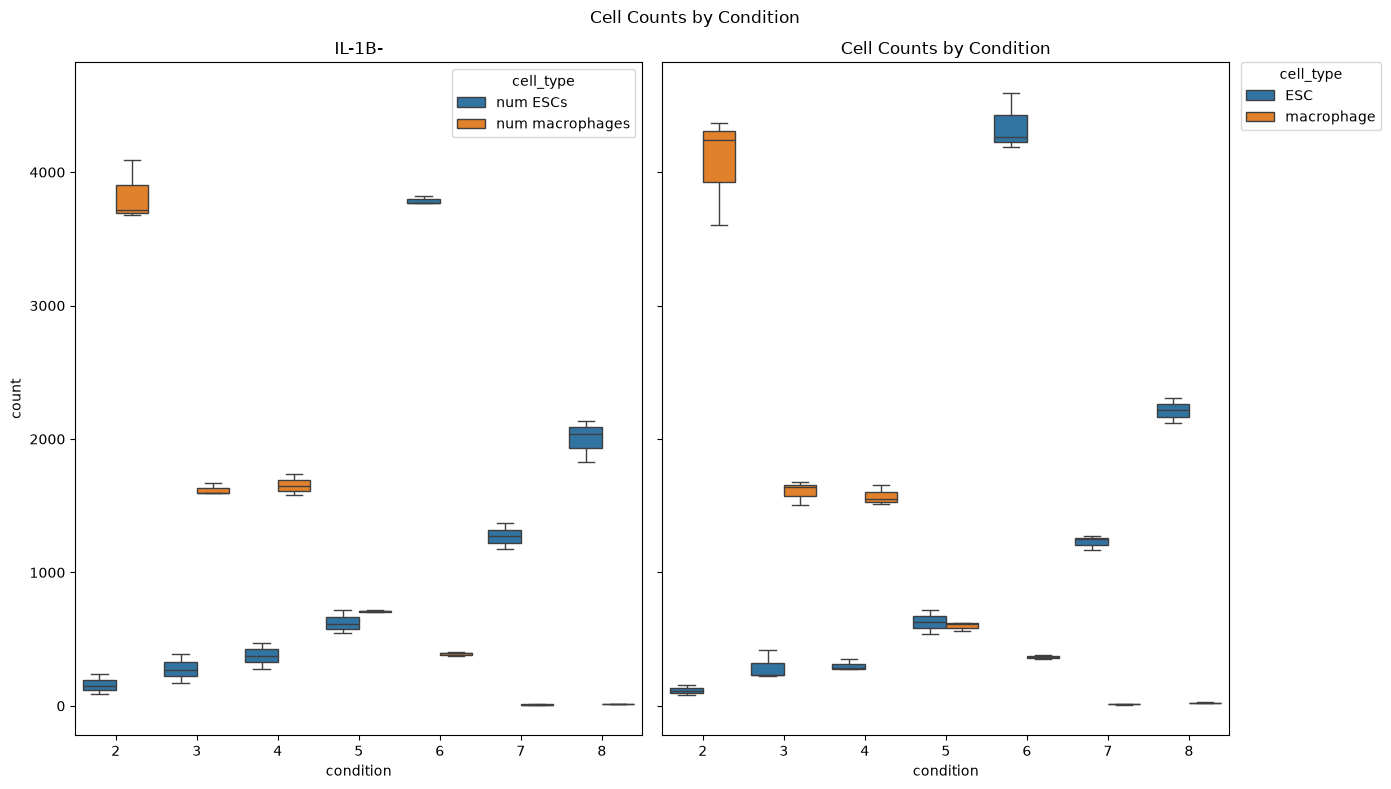

In [40]:
melted = df.melt(
    id_vars=['condition', 'saw_il1b'],
    value_vars=['num ESCs', 'num macrophages'],
    var_name='cell_type',
    value_name='count'
)

fig, axes = plt.subplots(1, 2, figsize=(14,8), sharey=True)

sns.boxplot(data=melted[~melted['saw_il1b']], x='condition', y='count', hue='cell_type', ax=axes[0])
axes[0].set_title('IL-1B-')

sns.boxplot(data=melted[melted['saw_il1b']], x='condition', y='count', hue='cell_type', ax=axes[1])
axes[1].set_title('IL-1B+')

handles, _ = plt.gca().get_legend_handles_labels()
fig.suptitle('Cell Counts by Condition')
plt.legend(handles, ['ESC', 'macrophage'], title='cell_type',
           bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.title('Cell Counts by Condition')
plt.tight_layout()
plt.show()

In [41]:
import plotly.express as px
import plotly.graph_objects as go
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

n_graphs = len(analytes)
current = {'i': 0}

output = widgets.Output()
btn_prev = widgets.Button(description='◀ Previous')
btn_next = widgets.Button(description='Next ▶')
label = widgets.Label()

def render():
    label.value = f"Graph {current['i']+1} / {n_graphs}"
    with output:
        clear_output(wait=True)
        cytokine = analytes[current['i']]

        x_col, y_col = 'num ESCs', 'num macrophages'
        sub = df[[x_col, y_col, cytokine]].dropna()

        # fit linear regression: cytokine ~ num_ESCs + num_macrophages
        X = sub[[x_col, y_col]].to_numpy()
        z = sub[cytokine].to_numpy()
        reg = LinearRegression().fit(X, z)
        r2 = r2_score(z, reg.predict(X))

        # build a grid over the observed x/y range for the fitted plane
        x_range = np.linspace(sub[x_col].min(), sub[x_col].max(), 20)
        y_range = np.linspace(sub[y_col].min(), sub[y_col].max(), 20)
        x_grid, y_grid = np.meshgrid(x_range, y_range)
        z_grid = reg.predict(
            np.column_stack([x_grid.ravel(), y_grid.ravel()])
        ).reshape(x_grid.shape)

        # scatter of the actual points
        fig = px.scatter_3d(sub, x=x_col, y=y_col, z=cytokine)
        fig.update_traces(marker=dict(size=4))

        # add the regression surface
        fig.add_trace(go.Surface(
            x=x_range, y=y_range, z=z_grid,
            opacity=0.5, showscale=False, colorscale='Reds',
            name='Linear fit'
        ))

        fig.update_layout(
            title=f"{cytokine}  (R² = {r2:.3f})",
            scene=dict(
                xaxis_title=x_col,
                yaxis_title=y_col,
                zaxis_title=cytokine
            )
        )
        fig.show()

def on_next(b):
    current['i'] = min(current['i'] + 1, n_graphs - 1)
    render()

def on_prev(b):
    current['i'] = max(current['i'] - 1, 0)
    render()

btn_next.on_click(on_next)
btn_prev.on_click(on_prev)

display(widgets.HBox([btn_prev, btn_next]), label, output)
render()

Label(value='')

Output()

In [42]:
import statsmodels.api as sm
import numpy as np

# regression cytokine ~ ESC/macrophage, within +IL-1B and -IL-1B groups
df['ESC:macrophage'] = df['num ESCs'] / df['num macrophages']

n_graphs = len(analytes)
current = {'i': 0}

output = widgets.Output()
btn_prev = widgets.Button(description='◀ Previous')
btn_next = widgets.Button(description='Next ▶')
label = widgets.Label()

group_colors = {True: 'tab:orange', False: 'tab:blue'}
group_titles = {True: 'IL-1B+', False: 'IL-1B-'}

def render():
    label.value = f"Graph {current['i']+1} / {n_graphs}"
    with output:
        clear_output(wait=True)
        cytokine = analytes[current['i']]
        x_col = 'ESC:macrophage'

        fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

        for ax, (il1b_val, color) in zip(axes, group_colors.items()):
            sub = df[df['saw_il1b'] == il1b_val][[x_col, cytokine]].dropna()

            ax.scatter(sub[x_col], sub[cytokine], color=color, alpha=0.7)

            if len(sub) >= 2:
                X = sub[x_col].to_numpy()
                y = sub[cytokine].to_numpy()

                X_design = sm.add_constant(X)  # adds intercept column
                model = sm.OLS(y, X_design).fit()
                r2 = model.rsquared

                x_line = np.linspace(X.min(), X.max(), 100)
                x_line_design = sm.add_constant(x_line)

                pred = model.get_prediction(x_line_design)
                pred_summary = pred.summary_frame(alpha=0.32)  # ~1 SE band (≈68% CI)

                y_line = pred_summary['mean']
                se_lower = pred_summary['mean_ci_lower']
                se_upper = pred_summary['mean_ci_upper']

                ax.plot(x_line, y_line, color=color, linewidth=2)
                ax.fill_between(x_line, se_lower, se_upper, color=color, alpha=0.2)

                ax.set_title(f"{group_titles[il1b_val]} (R² = {r2:.3f})")
            else:
                ax.set_title(f"{group_titles[il1b_val]} (insufficient data)")

            ax.set_xlabel(x_col)

        axes[0].set_ylabel(cytokine)
        fig.suptitle(f"{cytokine} vs {x_col}")

        fig.tight_layout()
        plt.show()

def on_next(b):
    current['i'] = min(current['i'] + 1, n_graphs - 1)
    render()

def on_prev(b):
    current['i'] = max(current['i'] - 1, 0)
    render()

btn_next.on_click(on_next)
btn_prev.on_click(on_prev)

display(widgets.HBox([btn_prev, btn_next]), label, output)
render()

Label(value='')

Output()

<Axes: xlabel='num macrophages', ylabel='num ESCs'>

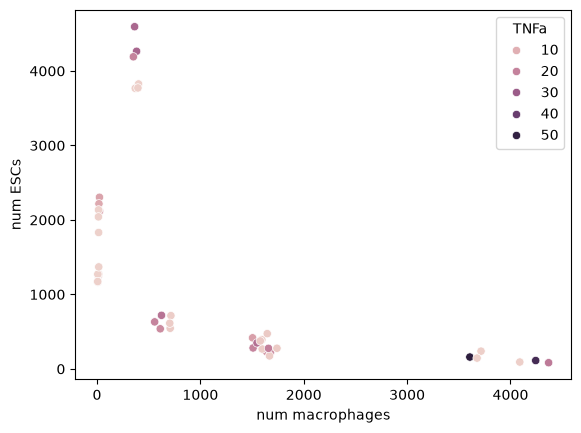

In [43]:
sns.scatterplot(df, x='num macrophages', y='num ESCs', hue = 'TNFa')

### Differential expression (+/- IL-1B)

In [44]:
df = pd.read_csv('16/data/luminex_wrangled.csv')
df['analyte'] = df['analyte'].str.split('_').str[0]

# aggregate by condition
df = df.dropna(subset='concentration').groupby(['condition', 'bio_rep', 'analyte', 'saw_il1b'])[['concentration']].mean().reset_index()

# pivot such that each row represents a condition and each column represents an analyte
df = df.pivot_table(index=['condition', 'bio_rep', 'saw_il1b'], columns='analyte', values='concentration').reset_index()

df.head()

analyte,condition,bio_rep,saw_il1b,CCL2,CCL3,CCL4,CCL5,CXCL1,CXCL10,CXCL13,...,IL4,IL6,IL8,MMP1,MMP12,MMP7,MMP9,SLPI,TNFa,VCAM1
0,2,B,True,128.092912,196.315587,180.255075,18.683765,286.861925,0.811973,17.334325,...,14.250662,7.282125,996.419599,215.817830,21.326560,NaN,2284.211089,135.444983,22.089125,3991.900206
1,2,C,True,147.588878,328.008249,312.403835,18.750801,353.508812,0.847524,18.433529,...,14.155242,13.678140,1827.622117,223.024103,21.224241,NaN,3547.846363,135.444983,46.381542,3926.820733
2,2,D,True,174.469551,372.433310,346.689129,18.885011,503.552940,0.859387,18.937332,...,14.345939,26.576676,2318.681340,253.794125,21.445930,NaN,3760.342219,135.444983,51.205990,3991.900206
3,2,E,False,116.758832,55.700796,90.715901,18.482931,240.603217,0.711559,16.370035,...,14.345939,NaN,98.614609,198.210568,21.582350,NaN,3194.437016,133.562245,3.389384,3894.196114
4,2,F,False,115.988406,52.545943,92.515446,18.549830,165.449009,0.829742,15.837237,...,15.009005,NaN,85.964039,192.030042,21.599402,NaN,2691.005635,131.665457,3.368707,3926.820733


In [45]:
melted = df.melt(
    id_vars=['condition', 'bio_rep', 'saw_il1b'],
    value_vars=analytes,
    var_name='cytokine',
    value_name='value'
)

# log2-transform each replicate (add pseudocount if you ever hit 0/negative values)
melted['log2fc'] = np.log2(melted['value'])

# per condition x cytokine x saw_il1b: mean and SE across tech reps (skips NAs automatically)
stats = (
    melted
    .groupby(['condition', 'cytokine', 'saw_il1b'])['log2fc']
    .agg(mean='mean', std='std', n='count')
    .reset_index()
)
stats['se'] = stats['std'] / np.sqrt(stats['n'])

# pivot so +/- IL1B sit side by side, then compute logFC and propagated SE
pivoted = stats.pivot(index=['condition', 'cytokine'], columns='saw_il1b', values=['mean', 'se'])

logfc_df = pd.DataFrame({
    'logFC': pivoted[('mean', True)] - pivoted[('mean', False)],
    'se':    np.sqrt(pivoted[('se', True)]**2 + pivoted[('se', False)]**2)
}).reset_index()

In [46]:
conditions = melted['condition'].unique()
n_graphs = len(conditions)
current = {'i': 0}

output = widgets.Output()
btn_prev = widgets.Button(description='◀ Previous')
btn_next = widgets.Button(description='Next ▶')
label = widgets.Label()

def render():
    label.value = f"Graph {current['i']+1} / {n_graphs}"
    with output:
        clear_output(wait=True)
        cond = conditions[current['i']]
        plot_condition(logfc_df, cond)

def on_next(b):
    current['i'] = min(current['i'] + 1, n_graphs - 1)
    render()

def on_prev(b):
    current['i'] = max(current['i'] - 1, 0)
    render()

btn_next.on_click(on_next)
btn_prev.on_click(on_prev)

display(widgets.HBox([btn_prev, btn_next]), label, output)
render()

Label(value='')

Output()